# 日本储能：电池寿命与衰减 v2.3

A官方资料、B计算、C假设分别保留。2MW/8.14MWh，278天历史年化不是长期预测。运行目录须为模块根；Python需要NumPy、SciPy、PyMuPDF、Matplotlib，Node24。计算输出写入源码树之外的独立runtime，原始资料不改写。


## 原始证据与保护资产


In [1]:
from pathlib import Path
import os,json,hashlib,subprocess,uuid,sys,math
import numpy as np
import pymupdf as fitz
ROOT=Path.cwd().resolve()
assert (ROOT/'research/feasibility/sources.json').exists()
read=lambda p:json.loads((ROOT/p).read_text(encoding='utf8'))
sha=lambda p:hashlib.sha256(p.read_bytes()).hexdigest()
S=read('research/feasibility/sources.json');source={s['id']:s for s in S}
baseline=read('research/feasibility/baseline.json')
for p,v in baseline['protected_files'].items():assert sha(ROOT/p)==v,p
for s in S:
 if s['status']=='downloaded':assert sha(ROOT/s['raw_file'])==s['sha256'],s['id']
# Runtime is a sibling directory, outside this source tree and any frozen package.
runtime=Path(os.environ.get('JAPAN_BESS_NOTEBOOK_RUNTIME',str(ROOT.parent/'bess-notebook-runtime'))).resolve()
assert not runtime.is_relative_to(ROOT)
SCRATCH=runtime/('v23-'+uuid.uuid4().hex[:10]);SCRATCH.mkdir(parents=True)
OUT=SCRATCH/'research';OUT.mkdir();sys.path.insert(0,str(ROOT/'scripts'))
def run(command,timeout=900):
 p=subprocess.run(command,cwd=ROOT,text=True,encoding='utf8',capture_output=True,timeout=timeout)
 assert p.returncode==0,(command,p.stdout[-1000:],p.stderr[-1000:])
 print(p.stdout[-500:]);return p
def check_tree(a,b):
 if isinstance(a,dict):
  assert set(a)==set(b)
  for k,v in a.items():check_tree(v,b[k])
 elif isinstance(a,list):
  assert len(a)==len(b)
  if a and all(isinstance(x,(int,float)) and not isinstance(x,bool) for x in a):
   np.testing.assert_allclose(a,b,rtol=1e-9,atol=1e-7)
  else:
   for x,y in zip(a,b):check_tree(x,y)
 elif isinstance(a,(int,float)) and not isinstance(a,bool):assert math.isclose(a,b,rel_tol=1e-9,abs_tol=1e-7),(a,b)
 else:assert a==b,(a,b)
def payload(dispatch):
 import prepare_feasibility_assumptions as fa,prepare_feasibility_grid as fg
 fa.prepare(OUT);fg.prepare(OUT)
 check_tree(json.loads((OUT/'assumptions.json').read_text(encoding='utf8')),read('research/feasibility/assumptions.json'))
 run(['node','scripts/prepare_feasibility_payload.mjs','--output-directory',str(OUT),'--dispatch-directory',str(dispatch),'--site-directory','none'])
 return json.loads((OUT/'economics-output.json').read_text(encoding='utf8'))
def graph(title,series,labels,ylabel,filename):
 import matplotlib;matplotlib.use('Agg')
 import matplotlib.pyplot as plt
 from matplotlib.font_manager import FontProperties
 font=FontProperties(fname='C:/Windows/Fonts/msyh.ttc')
 fig,ax=plt.subplots(figsize=(8,3.6));x=np.arange(len(labels))
 for name,values in series:ax.plot(x,values,marker='o',label=name)
 ax.set_xticks(x);ax.set_xticklabels(labels,fontproperties=font,fontsize=8);ax.set_title(title,fontproperties=font);ax.set_ylabel(ylabel,fontproperties=font)
 ax.axhline(0,color='#718096',linewidth=.6);ax.grid(alpha=.15);ax.legend(prop=font,loc='upper left',bbox_to_anchor=(0,-.15),frameon=False)
 fig.tight_layout();p=SCRATCH/filename;fig.savefig(p,dpi=150,bbox_inches='tight');plt.close(fig)
 GRAPHFILES.append(p)
 try:
  from IPython.display import display,Image
  display(Image(filename=str(p)))
 except ImportError:print('Rendered',p.name)
print('19 official records; 16 raw downloads; 215 protected assets verified; scratch',SCRATCH.name)
GRAPHFILES=[]


19 official records; 16 raw downloads; 215 protected assets verified; scratch v23-606e01d4ea


## LFP参照及C运营策略


In [2]:
doc=fitz.open(ROOT/source['pnnl-cost-life']['raw_file']);text=doc[43].get_text()
assert '2,475' in text and '6,250' in text
sam=(ROOT/source['nlr-sam-life']['body_file']).read_text(encoding='utf8');assert 'calendar' in sam.lower() and 'cycle' in sam.lower()
A=read('research/feasibility/assumptions.json')
print('PNNL reference2475–6250 cycles at80%DoD; not warranty. Applied EFC2400/3600/5000 and additive calendar/cycle model are C, not SAM reproduction.')
for k,p in A['policies'].items():print(k,p)


PNNL reference2475–6250 cycles at80%DoD; not warranty. Applied EFC2400/3600/5000 and additive calendar/cycle model are C, not SAM reproduction.
conservative {'title': '保守运营', 'socMin': 0.2, 'socMax': 0.8, 'maxCycles': 0.6}
base {'title': '基准运营', 'socMin': 0.1, 'socMax': 0.9, 'maxCycles': 1}
aggressive {'title': '积极运营', 'socMin': 0.05, 'socMax': 0.95, 'maxCycles': 1.5}


## 全量33,360次实际DP复算与寿命递推


In [3]:
# Force full rerun: three policy workers, all 4cases x 5regions x 2reserve x 278days.
dispatch=SCRATCH/'dispatch';dispatch.mkdir()
workers=[subprocess.Popen(['node','scripts/prepare_feasibility_dispatch.mjs','--policy',policy,'--output-directory',str(dispatch),'--force'],cwd=ROOT,stdout=subprocess.PIPE,stderr=subprocess.PIPE,text=True,encoding='utf8') for policy in ['conservative','base','aggressive']]
from concurrent.futures import ThreadPoolExecutor
with ThreadPoolExecutor(max_workers=3) as pool:
 outputs=list(pool.map(lambda worker:worker.communicate(timeout=900),workers))
for worker,(out,err) in zip(workers,outputs):
 assert worker.returncode==0,(out[-500:],err);print(out.splitlines()[-1])
count=0
for file in sorted((dispatch/'dispatch-cases').glob('*.json')):
 regenerated=json.loads(file.read_text(encoding='utf8'));saved=read('research/feasibility/dispatch-cases/'+file.name)
 check_tree(regenerated,saved);count+=len(regenerated['daily'])
assert count==33360
print('Every original chargeMW/dischargeMW/SOC vector, EFC, DoD, cash and information cutoff reproduced for33,360 optimizations;1,601,280 settled slots.')
E=payload(dispatch/'dispatch-cases');D=json.loads((OUT/'degradation-output.json').read_text(encoding='utf8'))
check_tree(D,read('research/feasibility/degradation-output.json'))
print('360 independent policy/age/region/case/reserve lifetime paths and marginal comparisons reproduced.')


{"status":"passed","executedSchedules":11120,"sourceHashCheckedReusedSchedules":0,"policy":"conservative","all_slot_physical_and_cutoff_checks":"passed"}
{"status":"passed","executedSchedules":11120,"sourceHashCheckedReusedSchedules":0,"policy":"base","all_slot_physical_and_cutoff_checks":"passed"}
{"status":"passed","executedSchedules":11120,"sourceHashCheckedReusedSchedules":0,"policy":"aggressive","all_slot_physical_and_cutoff_checks":"passed"}
Every original chargeMW/dischargeMW/SOC vector, EFC, DoD, cash and information cutoff reproduced for33,360 optimizations;1,601,280 settled slots.
Prepared explicit projectC assumptions and 9 separate primary reference observations
Normalized five comparable regional application observations; no site approval or hidden score
:137252495.7971161,"breakEvenAnnualOperatingContribution":87405036.80852945},{"cost":"high","initialInvestment":839000000.0000001,"annualOperatingContribution":27567702.56776736,"year1FreeCashflow":9372702.56776736,"npv":-

## SOH图、更换及边际价值


Rendered battery-soh.png
conservative cash 26338229 EFC 214.28 NPV -500006467 replacement [13]
base cash 27567703 EFC 304.56 NPV -566197591 replacement [10, 19]
aggressive cash 27925482 EFC 330.9 NPV -580413558 replacement [9, 17]
REPLAY_PASSED: public lifetime sources -> disclosed C -> full DP rerun -> EFC/DoD -> SOH -> replacement cash -> lifetime NPV -> chart contract.


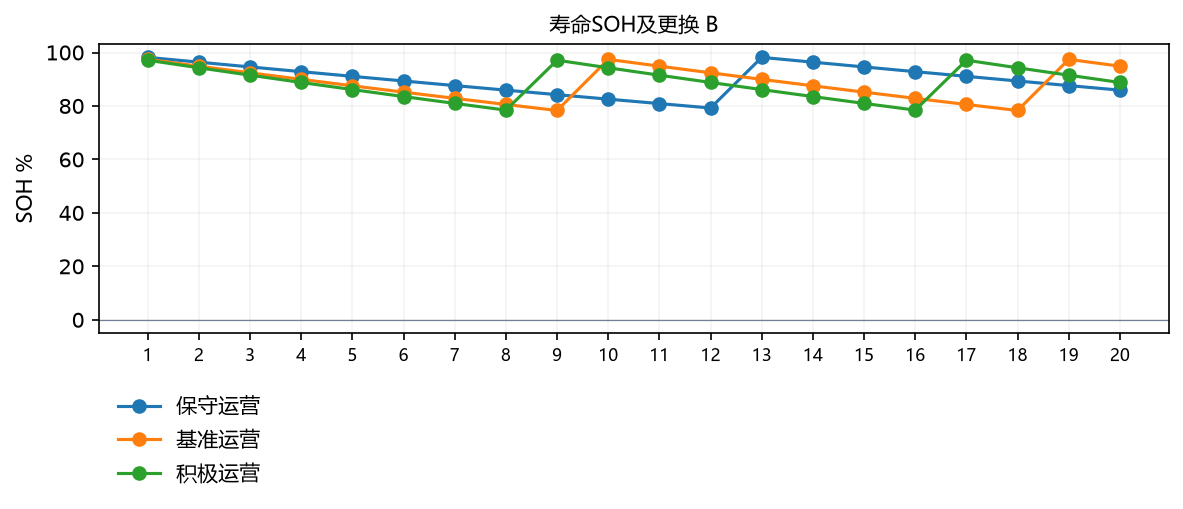

In [4]:
entries=[x for x in D['comparisons'] if x['scenario']=='base' and x['region']=='chubu' and x['ageID']=='base' and x['reserveMW']==1]
R=read('research/feasibility/report-data.json');contract=next(f for f in R['figures'] if f['id']=='soh')
for e,s in zip(entries,contract['series'][:3]):np.testing.assert_allclose([y['sohEnd']*100 for y in e['life']['years']],s['values'])
graph('寿命SOH及更换 B',[(A['policies'][e['policyID']]['title'],[y['sohEnd']*100 for y in e['life']['years']]) for e in entries],[str(y['year']) for y in entries[0]['life']['years']],'SOH %','battery-soh.png')
for e in entries:print(e['policyID'],'cash',round(e['year1Cash']),'EFC',round(e['year1EFC'],2),'NPV',round(e['finance']['npv']),'replacement',[y['year'] for y in e['life']['years'] if y['replacement']])
for p,v in baseline['protected_files'].items():assert sha(ROOT/p)==v
print('REPLAY_PASSED: public lifetime sources -> disclosed C -> full DP rerun -> EFC/DoD -> SOH -> replacement cash -> lifetime NPV -> chart contract.')
